<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 006 Kalibrasi dari Pertandingan Lain</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Eksperimen 005 menunjukkan bahwa laju pergantian possession tidak teridentifikasi dari bukti per frame: EM biasa menghasilkan sekitar 1.060 possession, EM yang dikoreksi autokorelasi hanya 47 sampai 95, dan konstanta tangan λ = 50 (191 possession) berada di antaranya tanpa dasar. Satu-satunya jalan yang diizinkan `RULES.md` untuk mendapat informasi itu adalah **data pertandingan lain**.

Eksperimen ini mengambil statistik possession dari **data peristiwa terbuka StatsBomb** pada sampel pertandingan La Liga 2018/19 (24 pertandingan Barcelona), lalu memilih biaya ganti λ sehingga jumlah possession prediksi per menit sesuai dengan acuan itu. Tidak ada satu pun statistik dari ground truth pertandingan ini yang dipakai.

Data pertandingan lain diizinkan dengan syarat bisa diakses panitia dan dijelaskan di dokumen teknis; sumber, sampel, dan statistik yang dipakai dituliskan di bawah. Hanya angka agregat yang dipakai, dan berkas mentah disimpan di `experiments/_cache/ext/` (tidak di-commit).


# Metodologi

**StatsBomb open data (pertandingan lain) → possession per menit → target jumlah possession untuk 105,9 menit dinilai → sapuan λ pada decoder Viterbi → λ* yang mencocokkan target → gap bola mati dari 004 → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

| asumsi | nilai | alasan |
|---|---|---|
| sumber acuan | StatsBomb open data, La Liga 2018/19, 24 dari 34 pertandingan (sampel acak, seed 7) | data peristiwa terbuka pertandingan lain; semuanya pertandingan Barcelona seperti yang dinilai |
| statistik acuan | possession per menit (dari kick-off hingga peristiwa terakhir tiap babak) | agregat, tidak bergantung pada pemain tertentu |
| definisi | possession StatsBomb ≈ possession tantangan | **tidak identik** (lihat catatan di [1]); ini risiko utama |
| bukti tim | skor kendali lunak σ = 3 m dengan skala dari EM biasa (005); dan bukti terdekat τ = 3 m | dua bukti dari 005 |

# Environment

Dijalankan dari dalam repositori. Satu-satunya akses jaringan adalah mengunduh data peristiwa terbuka pertandingan **lain** (berkas publik di GitHub). Tidak ada data pertandingan ini yang dikirim ke mana pun.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import json, random, subprocess, urllib.request
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25
N = source_frames("tactical")
BLOCKS3 = half_video_blocks("BAR-ATH")
BL = [(a, b) for _, a, b in BLOCKS3]
GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS3: GRADED[a:b + 1] = True
GRADED_MIN = GRADED.sum() / FPS / 60
OUT = Path(common.HERE) / "006_external_calibration" / "out"; OUT.mkdir(parents=True, exist_ok=True)
EXT = Path(common.CACHE) / "ext"; EXT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
print(f"frames: {N} | dinilai: {GRADED.sum()} ({GRADED_MIN:.1f} menit)")

frames: 199319 | dinilai: 158857 (105.9 menit)


# Approach: Kalibrasi Biaya Ganti dari Pertandingan Lain

## [1] Statistik possession dari pertandingan lain

Setiap berkas peristiwa StatsBomb memiliki indeks `possession` dan cap waktu. Untuk tiap pertandingan dihitung: jumlah possession, total menit (dari peristiwa pertama sampai terakhir di tiap babak), laju possession per menit, serta durasi dari awal sebuah possession ke awal possession berikutnya.

pertandingan tersedia: 34 | sampel: 24


possession per menit: 1.96 (SD 0.19) | possession per pertandingan: 186 (150 sampai 226)
awal-ke-awal persentil 10/25/50/75/90 (dtk): [ 3.4  9.1 22.3 42.7 70.2]
target untuk 105.9 menit dinilai: 208 +/- 21 possession


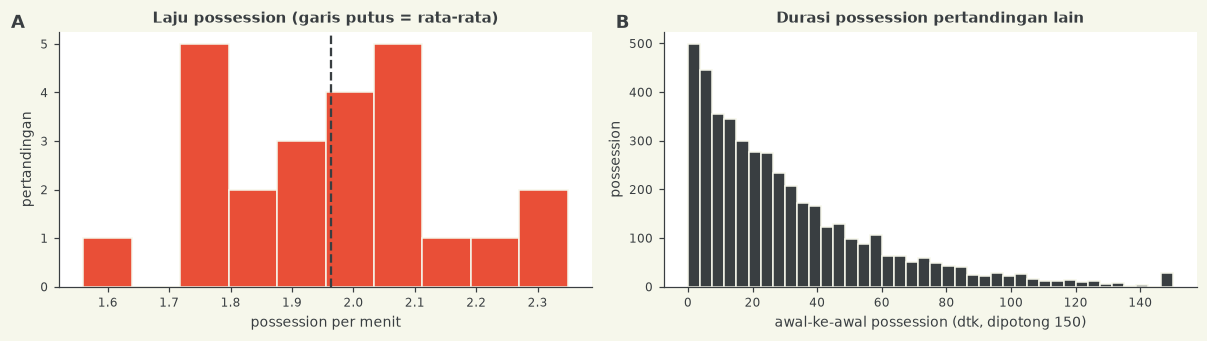

In [2]:
BASE = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"
def fetch(url, path):
    if not path.exists():
        with urllib.request.urlopen(url, timeout=90) as r: path.write_bytes(r.read())
    return json.loads(path.read_text())

matches = fetch(f"{BASE}/matches/11/4.json", EXT / "matches_11_4.json")
random.seed(7)
ids = [m["match_id"] for m in random.sample(matches, 24)]
print("pertandingan tersedia:", len(matches), "| sampel:", len(ids))

def ts(e):
    h, m, s = e["timestamp"].split(":"); return int(h) * 3600 + int(m) * 60 + float(s)

rows, gaps = [], []
for mid in ids:
    ev = [e for e in fetch(f"{BASE}/events/{mid}.json", EXT / f"ev_{mid}.json") if e.get("period") in (1, 2) and "possession" in e]
    minutes = 0.0
    for p in (1, 2):
        t = [ts(e) for e in ev if e["period"] == p]
        minutes += (max(t) - min(t)) / 60
    seg = {}
    for e in ev:
        k = (e["period"], e["possession"]); t = ts(e); a = seg.setdefault(k, [t, t]); a[0] = min(a[0], t); a[1] = max(a[1], t)
    keys = sorted(seg, key=lambda k: (k[0], seg[k][0]))
    g = [seg[b][0] - seg[a][0] for a, b in zip(keys[:-1], keys[1:]) if a[0] == b[0]]
    gaps += g
    rows.append({"match_id": mid, "possession": len(keys), "menit": round(minutes, 1), "per menit": len(keys) / minutes, "rata2 awal-ke-awal (dtk)": np.mean(g)})
EXTDF = pd.DataFrame(rows)
RATE, RATE_SD = EXTDF["per menit"].mean(), EXTDF["per menit"].std()
TARGET, TARGET_SD = RATE * GRADED_MIN, RATE_SD * GRADED_MIN
EXT_PCT = np.percentile(gaps, [10, 25, 50, 75, 90])
print(f"possession per menit: {RATE:.2f} (SD {RATE_SD:.2f}) | possession per pertandingan: {EXTDF.possession.mean():.0f} ({EXTDF.possession.min()} sampai {EXTDF.possession.max()})")
print(f"awal-ke-awal persentil 10/25/50/75/90 (dtk): {EXT_PCT.round(1)}")
print(f"target untuk {GRADED_MIN:.1f} menit dinilai: {TARGET:.0f} +/- {TARGET_SD:.0f} possession")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(EXTDF["per menit"], bins=10, color=C1, edgecolor=C3); ax[0].axvline(RATE, color=INK, ls="--")
ax[0].set(xlabel="possession per menit", ylabel="pertandingan", title="Laju possession (garis putus = rata-rata)")
ax[1].hist(np.clip(gaps, 0, 150), bins=40, color=C2, edgecolor=C3); ax[1].set(xlabel="awal-ke-awal possession (dtk, dipotong 150)", ylabel="possession", title="Durasi possession pertandingan lain")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

**Catatan definisi (risiko utama).** Possession StatsBomb mensyaratkan kendali dan memasukkan jeda sampai possession berikutnya, sedangkan possession tantangan ini adalah *run maksimal H atau A saat bola hidup*, sehingga bisa lebih halus (lebih banyak possession pendek). README mempublikasikan 17 possession dalam 5 menit pada jendela GT publik, yaitu laju yang lebih tinggi daripada 1,96 per menit, tetapi itu hanya sampel 5 menit dari satu pertandingan dan tidak boleh dipakai untuk menyetel. Acuan eksternal ini jadi **penentu skala**, bukan pengukuran presisi; sapuan di bawah memperlihatkan bagaimana λ bergeser bila targetnya berubah.

## [2] Decoder dan sapuan λ

Dua jenis bukti dari 005: skor kendali lunak σ = 3 m (skala emisi dari EM biasa, yang stabil antar babak) dan bukti terdekat dengan τ = 3 m. Untuk tiap λ dihitung jumlah possession prediksi pada frame dinilai (setelah gap bola mati 004 menjadi `D`).

In [3]:
G = common.gap_dead_ball(); DEAD = G[G.p_dead >= 0.5]
C_S3, OBS_S3 = common.soft_control(3.0)
P_S3 = common.hmm2_em(C_S3, OBS_S3, BL, n_iter=60, tol=1e-6)         # EM biasa: hanya untuk skala m dan s
dist = common.team_distances(); dH, dA = dist[:, 0], dist[:, 1]
OBS_N = np.isfinite(dH) & np.isfinite(dA)
E_N = np.zeros(N); E_N[OBS_N] = np.clip((dA[OBS_N] - dH[OBS_N]) / 3.0, -10, 10)

def lps(kind):
    if kind == "lunak3":
        o, c = OBS_S3, C_S3
        h = np.where(o, -0.5 * ((c - P_S3["m"]) / P_S3["s"]) ** 2, 0.0); a = np.where(o, -0.5 * ((c + P_S3["m"]) / P_S3["s"]) ** 2, 0.0)
    else:
        h, a = -np.logaddexp(0, -E_N), -np.logaddexp(0, E_N); h[~OBS_N] = 0; a[~OBS_N] = 0
    return h, a
LP = {k: lps(k) for k in ("lunak3", "terdekat")}

def finish(paths):
    lab = np.full(N, "X", dtype="<U1")
    for (half, a, b), p in zip(BLOCKS3, paths):
        lab[a:b + 1] = np.where(p == 0, "H", "A")
        if half == 2: lab[a:KICKOFF2] = "D"
    for _, r in DEAD.iterrows(): lab[int(r.f0):int(r.f1)] = "D"
    return lab

def decode(kind, lam):
    h, a = LP[kind]
    return finish([common.viterbi_2state(h[x:y + 1], a[x:y + 1], lam) for x, y in BL])

def possession_starts(lab):
    out = []
    for _, a, b in BLOCKS3:
        seg = lab[a:b + 1]
        st = []
        for t in ("H", "A"):
            s, e = common.runs(seg == t); st += list(s)
        out.append(np.sort(st))
    return out

def count_and_median(lab):
    st = possession_starts(lab)
    n = sum(len(s) for s in st)
    gaps_ = np.concatenate([np.diff(s) / FPS for s in st if len(s) > 1])
    return n, gaps_

LAMS = [5, 10, 20, 30, 50, 80, 120, 200, 400]
SWEEP = {k: [] for k in LP}
for k in LP:
    for lam in LAMS:
        n, g = count_and_median(decode(k, lam))
        SWEEP[k].append({"λ": lam, "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1)})
for k in LP:
    print(k); display(pd.DataFrame(SWEEP[k]).T)

lunak3


,0,1,2,3,4,5,6,7,8
λ,5.0,10.0,20.0,30.0,50.0,80.0,120.0,200.0,400.0
possession,1033.0,849.0,640.0,524.0,418.0,319.0,255.0,199.0,131.0
median awal-ke-awal (dtk),2.2,2.8,4.3,5.7,7.3,11.3,15.1,22.0,40.1


terdekat


,0,1,2,3,4,5,6,7,8
λ,5.0,10.0,20.0,30.0,50.0,80.0,120.0,200.0,400.0
possession,696.0,477.0,305.0,247.0,191.0,146.0,134.0,108.0,67.0
median awal-ke-awal (dtk),3.5,6.2,12.0,18.1,24.6,31.8,38.0,43.6,68.4


## [3] Memilih λ* dari target eksternal

Jumlah possession menurun terhadap λ. λ* adalah nilai (interpolasi linear pada log λ) di mana jumlah prediksi sama dengan target eksternal, dan pita ±1 SD memberi kisaran λ yang konsisten dengan acuan.

,λ*,λ (+1 SD jumlah),λ (-1 SD jumlah)
lunak3,184.3,152.7,225.3
terdekat,42.8,35.5,52.0


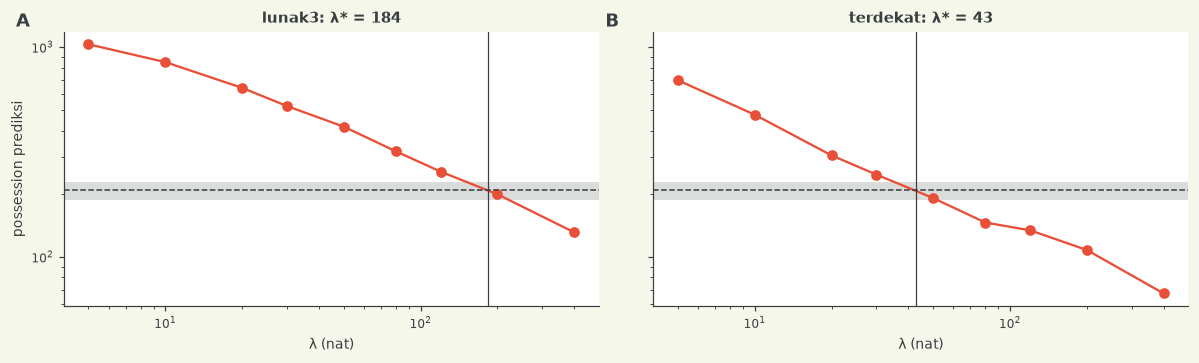

In [4]:
def solve(kind, target):
    x = np.log([r["λ"] for r in SWEEP[kind]]); y = np.array([r["possession"] for r in SWEEP[kind]], float)
    if target >= y[0]: return float(np.exp(x[0]))
    if target <= y[-1]: return float(np.exp(x[-1]))
    return float(np.exp(np.interp(-target, -y, x)))

CAL = {}
for k in LP:
    CAL[k] = {"λ*": solve(k, TARGET), "λ (+1 SD jumlah)": solve(k, TARGET + TARGET_SD), "λ (-1 SD jumlah)": solve(k, max(TARGET - TARGET_SD, 1))}
display(pd.DataFrame(CAL).T.round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, k in zip(ax, LP):
    a.plot([r["λ"] for r in SWEEP[k]], [r["possession"] for r in SWEEP[k]], marker="o", color=C1)
    a.axhspan(TARGET - TARGET_SD, TARGET + TARGET_SD, color=C2, alpha=0.18, lw=0); a.axhline(TARGET, color=C2, ls="--", lw=1)
    a.axvline(CAL[k]["λ*"], color=INK, lw=0.8); a.set(xscale="log", yscale="log", xlabel="λ (nat)", title=f"{k}: λ* = {CAL[k]['λ*']:.0f}")
ax[0].set_ylabel("possession prediksi"); panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

Pita abu-abu adalah target eksternal (rata-rata ± 1 SD antar pertandingan). Lebar pita pada sumbu λ menunjukkan seberapa kokoh pilihannya: pita yang sempit berarti λ cukup ditentukan oleh acuan, pita yang lebar berarti masih longgar.

## [4] Varian yang dibangun dan perbandingan distribusi durasi

Varian utama memakai λ* untuk tiap bukti. Dua varian pita (λ pada +1 SD dan −1 SD jumlah) memperlihatkan sensitivitas. Dibandingkan pula persentil durasi awal-ke-awal prediksi dengan acuan eksternal.

In [5]:
VARS = {"v1_soft3_cal": ("lunak3", CAL["lunak3"]["λ*"]), "v2_nearest_cal": ("terdekat", CAL["terdekat"]["λ*"]),
        "v3_soft3_band_hi": ("lunak3", CAL["lunak3"]["λ (-1 SD jumlah)"]), "v4_soft3_band_lo": ("lunak3", CAL["lunak3"]["λ (+1 SD jumlah)"]),
        "ref_004_lam50": ("terdekat", 50.0)}
for old in OUT.glob("*.csv"): old.unlink()
rows, pct = [], {"acuan eksternal": EXT_PCT}
for name, (k, lam) in VARS.items():
    lab = decode(k, lam); write_submission(str(OUT / f"{name}.csv"), lab)
    n, g = count_and_median(lab); pct[name] = np.percentile(g, [10, 25, 50, 75, 90])
    rows.append({"varian": name, "bukti": k, "λ": round(lam, 1), "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1), "% D (dinilai)": round(100 * np.mean(lab[GRADED] == "D"), 1)})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS3: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, g = count_and_median(base)
rows.append({"varian": "baseline_smooth50", "bukti": "terdekat", "λ": None, "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1), "% D (dinilai)": round(100 * np.mean(base[GRADED] == "D"), 1)})
display(pd.DataFrame(rows))
display(pd.DataFrame(pct, index=["P10", "P25", "P50", "P75", "P90"]).T.round(1))

,varian,bukti,λ,possession,median awal-ke-awal (dtk),% D (dinilai)
0,v1_soft3_cal,lunak3,184.3,210,21.6,22.7
1,v2_nearest_cal,terdekat,42.8,212,20.6,22.7
2,v3_soft3_band_hi,lunak3,225.3,171,28.3,22.7
3,v4_soft3_band_lo,lunak3,152.7,232,18.4,22.7
4,ref_004_lam50,terdekat,50.0,191,24.6,22.7
5,baseline_smooth50,terdekat,NaN,594,5.7,32.3


,P10,P25,P50,P75,P90
acuan eksternal,3.4,9.1,22.3,42.7,70.2
v1_soft3_cal,4.4,7.4,21.6,39.6,61.6
v2_nearest_cal,3.6,7.6,20.6,40.4,62.3
v3_soft3_band_hi,5.2,11.3,28.3,45.2,71.8
v4_soft3_band_lo,3.9,6.6,18.4,37.9,57.5
ref_004_lam50,3.9,7.7,24.6,43.1,69.9


## [5] Validasi dan skor (pemeriksaan pipeline)

Skor GT publik hanya memeriksa bahwa berkas benar. Dengan 17 possession, selisih kecil adalah noise dan tidak dipakai untuk memilih varian.

In [6]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

baseline_smooth50.csv -> VALID


ref_004_lam50.csv -> VALID


v1_soft3_cal.csv -> VALID


v2_nearest_cal.csv -> VALID


v3_soft3_band_hi.csv -> VALID


v4_soft3_band_lo.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,v2_nearest_cal,0.6644,0.5000,11,25.9418
1,2,v1_soft3_cal,0.6618,0.4857,11,25.9418
2,3,v3_soft3_band_hi,0.6618,0.4857,11,25.9418
3,4,v4_soft3_band_lo,0.6618,0.4857,11,25.9418
4,5,ref_004_lam50,0.6618,0.4000,9,31.7067
5,6,baseline_smooth50,0.6207,0.3256,26,10.8031


# Ringkasan 006

**Yang dikerjakan.** Dari 24 pertandingan Barcelona lain (data peristiwa terbuka StatsBomb, La Liga 2018/19) dihitung laju possession: 1,96 per menit (SD 0,19), sekitar 186 per pertandingan, median awal-ke-awal 22,3 detik. Untuk 105,9 menit dinilai, targetnya 208 ± 21 possession. λ pada decoder Viterbi dipilih agar jumlah possession prediksi sama dengan target itu. Bola mati tetap dari pengklasifikasi gap 004. Semua enam berkas lolos `validate_submission.py`. Tidak ada statistik ground truth pertandingan ini yang dipakai; satu-satunya akses jaringan adalah mengunduh berkas publik pertandingan lain.

**Hasil.**
1. **Bukti terdekat:** λ* = 42,8 (pita ±1 SD: 35,5 sampai 52,0). Ini sangat dekat dengan konstanta tangan λ = 50 pada 004, jadi acuan eksternal **membenarkan konstanta itu setelah kejadian** dan memberinya dasar yang bisa dipertanggungjawabkan.
2. **Bukti lunak σ = 3 m:** λ* = 184 (pita 153 sampai 225). Angkanya berbeda empat kali dari bukti terdekat karena skala emisinya berbeda, bukan karena perilakunya; keduanya menghasilkan sekitar 210 possession.
3. **Distribusi durasi cocok dengan acuan, padahal hanya jumlahnya yang ditargetkan.** Persentil awal-ke-awal prediksi (P10/P25/P50/P75/P90) untuk λ* bukti terdekat adalah 3,6/7,6/20,6/40,4/62,3 detik, dibanding acuan eksternal 3,4/9,1/22,3/42,7/70,2 detik. Kecocokan bentuk ini bukti yang lebih independen daripada kecocokan jumlah.
4. **Pita sempit.** λ yang konsisten dengan acuan hanya berkisar sekitar ±20% untuk bukti terdekat, sehingga hasilnya tidak sensitif pada pilihan target dalam satu SD.

**Pemeriksaan pipeline (GT publik, 17 possession; bukan dasar pemilihan).** `v2_nearest_cal` 0,664 macroF1 dan 0,500 spellF1, `v1_soft3_cal` 0,662 dan 0,486, `ref_004_lam50` 0,662 dan 0,400, `baseline_smooth50` 0,621 dan 0,326. Ini papan tertinggi sejauh ini, tetapi selisihnya berada dalam noise 17 possession, jadi **tidak ada klaim perbaikan atas baseline**.

**Risiko utama.** Definisi possession StatsBomb tidak identik dengan tantangan ini. Tantangan memakai run maksimal H atau A saat bola hidup, yang bisa lebih halus. README mempublikasikan 17 possession dalam 5 menit pada GT publik (laju lebih tinggi daripada 1,96 per menit) sementara model memprediksi 11 pada jendela itu, konsisten dengan kemungkinan under-segmentasi. Satu jendela 5 menit tidak boleh dipakai untuk menyetel, jadi risiko ini dicatat, bukan dikoreksi. Keterbatasan lain: sampel acuan hanya 24 pertandingan Barcelona 2018/19, dan jumlah possession dikalibrasi, bukan ketepatan batasnya.

**Langkah berikutnya.** (a) Uji sensitivitas terhadap definisi dengan acuan lain (mis. data peristiwa liga lain) untuk melihat seberapa berubah λ*; (b) perbaiki ketepatan batas, karena kalibrasi jumlah tidak menjamin batas waktu yang benar (transisi pada GT publik hanya cocok 2 dari 20); (c) bukti video lokal untuk pergantian possession.